# Imports

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)   # generator naključnih števil (ponovljivost)

# Parametri energije
K, Gama, lam = 1.0, 1.0, 1.0     # utež ploščine, obsega in dolžin stranic
R = 1.0                          # polmer očrtanega kroga

# Funkcije

In [2]:
def poligon(R, n, eps=0.0, rng=rng):
    """Oglišča n-kotnika, vrisanega v krog s polmerom R (v pozitivni smeri).
    eps: relativni šum kota in polmera. Vrne array (n, 2)."""
    dfi = 2 * np.pi / n
    fi = dfi * np.arange(n) + rng.uniform(-eps, eps, n) * dfi
    r = R * (1 + rng.uniform(-eps, eps, n))
    return np.column_stack([r * np.cos(fi), r * np.sin(fi)])


def stranice(t):
    """Dolžine stranic poligona t (zadnje oglišče povežemo s prvim)."""
    return np.linalg.norm(np.roll(t, -1, axis=0) - t, axis=1)


def obseg(t):
    return stranice(t).sum()


def ploscina(t):
    """Ploščina po formuli vezalk (shoelace)."""
    x, y = t[:, 0], t[:, 1]
    return 0.5 * abs(np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y))


def tezisce(t):
    """Masno središče oglišč."""
    return t.mean(axis=0)


def referencne(R, n):
    """Analitične vrednosti za pravilni n-kotnik: (A0, P0, l0)."""
    l0 = 2 * R * np.sin(np.pi / n)
    return 0.5 * n * R**2 * np.sin(2 * np.pi / n), n * l0, l0


def energija(t, ref, K=K, Gama=Gama, lam=lam):
    """Mehanska energija celice; ref = (A0, P0, l0)."""
    A0, P0, l0 = ref
    return (0.5 * K * (ploscina(t) - A0)**2 + 0.5 * Gama * (obseg(t) - P0)**2
            + 0.5 * lam * np.sum((stranice(t) - l0)**2))


def relaksacija_mc(t, ref, n_iter=20_000, korak=0.05, T=0.0, prilagodi=True, p_cilj=(0.2, 0.3), rng=rng):
    """Relaksacija z metodo Monte Carlo. T = 0: pohlepni algoritem, T > 0: Metropolis.
    p_cilj: interval želenega deleža sprejetih potez (prilagajanje koraka).
    Vrne (t, E, delez_sprejetih, korak) kot arraye po iteracijah."""
    t = t.copy()
    E = energija(t, ref)
    zgod_E, zgod_p, zgod_k = [], [], []
    p = 0.5                       # drseče povprečje deleža sprejetih potez
    for it in range(1, n_iter + 1):
        i = rng.integers(len(t))
        staro = t[i].copy()
        t[i] += rng.uniform(-korak, korak, 2)
        E_nova = energija(t, ref)
        dE = E_nova - E
        if T > 0:
            sprejmi = dE < 0 or rng.random() < np.exp(-dE / T)
        else:
            sprejmi = dE < 0
        if sprejmi:
            E = E_nova
        else:
            t[i] = staro
        p = 0.99 * p + 0.01 * sprejmi
        if prilagodi:   # delež sprejetih držimo v intervalu p_cilj
            if p < p_cilj[0]:
                korak *= 0.99
            elif p > p_cilj[1]:
                korak *= 1.01
        zgod_E.append(E)
        zgod_p.append(p)
        zgod_k.append(korak)
    return t, np.array(zgod_E), np.array(zgod_p), np.array(zgod_k)


def narisi_celico(ax, t, barva="tab:orange", **kw):
    """Nariše poligon in njegovo težišče."""
    z = np.vstack([t, t[:1]])
    ax.fill(z[:, 0], z[:, 1], color=barva, alpha=0.3)
    ax.plot(z[:, 0], z[:, 1], "o-", color=barva, **kw)
    ax.plot(*tezisce(t), "k+", ms=10)
    ax.set_aspect("equal")

# Testno območje

In [3]:
for n in (4, 6):
    t = poligon(R, n)
    print(f"n = {n}: A = {ploscina(t):.4f}, P = {obseg(t):.4f}, l = {stranice(t)[0]:.4f}, "
          f"ref = {np.round(referencne(R, n), 4)}, E = {energija(t, referencne(R, n)):.2e}")

# P3: pravokotnik
t_p = np.array([[0, 0], [2, 0], [2, 1], [0, 1]], dtype=float)
print("pravokotnik: A =", ploscina(t_p), " težišče =", tezisce(t_p))

# P4: šestkotnik, povečan za faktor 1.1
print("E(1.1 * šestkotnik) =", energija(1.1 * poligon(R, 6), referencne(R, 6)))

n = 4: A = 2.0000, P = 5.6569, l = 1.4142, ref = [2.     5.6569 1.4142], E = 4.44e-31
n = 6: A = 2.5981, P = 6.0000, l = 1.0000, ref = [2.5981 6.     1.    ], E = 7.33e-31
pravokotnik: A = 2.0  težišče = [1.  0.5]
E(1.1 * šestkotnik) = 0.35883750000000125


# Naloga 1 - Slika 2

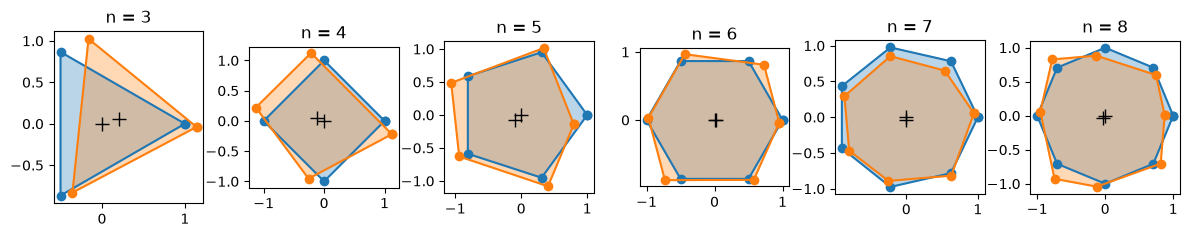

In [4]:
fig = plt.figure(figsize=(12, 3))
for k, n in enumerate(range(3, 9)):
    ax = fig.add_subplot(1, 6, k + 1)
    narisi_celico(ax, poligon(R, n), "tab:blue")
    narisi_celico(ax, poligon(R, n, eps=0.2), "tab:orange")
    ax.set_title(f"n = {n}")
fig.tight_layout()
plt.show()

# Naloga 1 - Slika 3

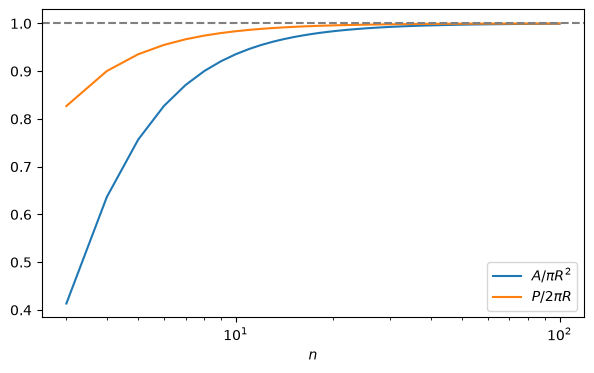

3 [1.299  5.1962] 0.4135 0.827
4 [2.     5.6569] 0.6366 0.9003
6 [2.5981 6.    ] 0.827 0.9549
12 [3.     6.2117] 0.9549 0.9886
100 [3.1395 6.2822] 0.9993 0.9998


In [5]:
n_v = np.arange(3, 101)
razmerje_A = np.array([ploscina(poligon(R, n)) for n in n_v]) / (np.pi * R**2)
razmerje_P = np.array([obseg(poligon(R, n)) for n in n_v]) / (2 * np.pi * R)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.semilogx(n_v, razmerje_A, label=r"$A/\pi R^2$")
ax.semilogx(n_v, razmerje_P, label=r"$P/2\pi R$")
ax.axhline(1, color="gray", ls="--")
ax.set_xlabel("$n$")
ax.legend()
plt.show()
# Preglednica 1
for n in (3, 4, 6, 12, 100):
    print(n, np.round(referencne(R, n)[:2], 4), round(ploscina(poligon(R, n)) / np.pi, 4), round(obseg(poligon(R, n)) / (2 * np.pi), 4))

# Naloga 2 - Slika 4

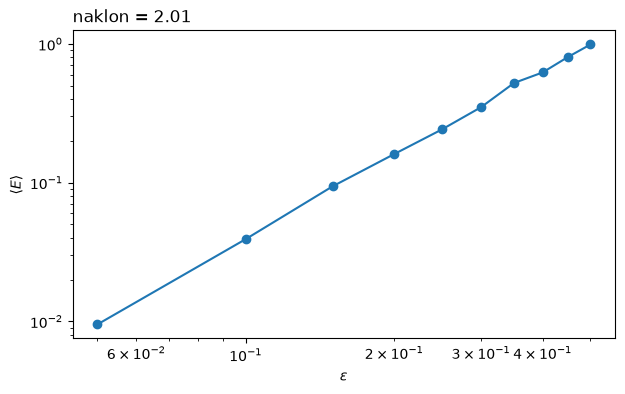

In [6]:
ref6 = referencne(R, 6)
eps_v = np.linspace(0, 0.5, 11)
E_eps = np.array([np.mean([energija(poligon(R, 6, e), ref6) for _ in range(200)]) for e in eps_v])
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.loglog(eps_v[1:], E_eps[1:], "o-")
k, n = np.polyfit(np.log10(eps_v[1:]), np.log10(E_eps[1:]), 1)
ax.set_title(f"naklon = {k:.2f}", loc="left")
ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$\langle E \rangle$")
plt.show()

In [7]:
# Preglednica 2: prispevki k energiji za en popačen šestkotnik (eps = 0.3)
t0 = poligon(R, 6, eps=0.3, rng=np.random.default_rng(7))
A0, P0, l0 = ref6
print(f"A = {ploscina(t0):.4f}, P = {obseg(t0):.4f}")
print(f"E_A = {0.5*K*(ploscina(t0)-A0)**2:.4f}, E_P = {0.5*Gama*(obseg(t0)-P0)**2:.4f}, "
      f"E_l = {0.5*lam*np.sum((stranice(t0)-l0)**2):.4f}, E = {energija(t0, ref6):.4f}")

A = 2.3448, P = 5.8245
E_A = 0.0321, E_P = 0.0154, E_l = 0.1019, E = 0.1494


# Naloga 3

In [8]:
t_kon, E_h, p_h, k_h = relaksacija_mc(t0, ref6, n_iter=20_000, korak=0.05)
print(f"E: {energija(t0, ref6):.4f} -> {E_h[-1]:.2e}")

E: 0.1494 -> 3.78e-07


# Naloga 3 - Slika 5

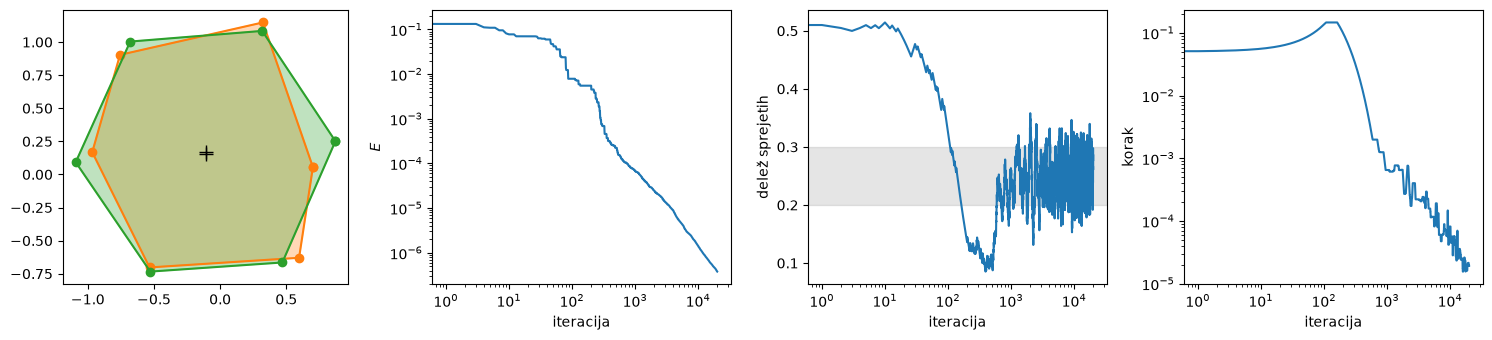

In [9]:
fig = plt.figure(figsize=(15, 3.5))
ax = fig.add_subplot(141)
narisi_celico(ax, t0, "tab:orange")
narisi_celico(ax, t_kon, "tab:green")
ax = fig.add_subplot(142)
ax.loglog(E_h)
ax.set_xlabel("iteracija")
ax.set_ylabel("$E$")
ax = fig.add_subplot(143)
ax.semilogx(p_h)
ax.axhspan(0.2, 0.3, color="gray", alpha=0.2)
ax.set_xlabel("iteracija")
ax.set_ylabel("delež sprejetih")
ax = fig.add_subplot(144)
ax.loglog(k_h)
ax.set_xlabel("iteracija")
ax.set_ylabel("korak")
fig.tight_layout()
plt.show()

In [10]:
# Preglednica 3: relaksacija za različne n
for n in (4, 6, 8, 12):
    ref = referencne(R, n)
    t_z = poligon(R, n, eps=0.3, rng=np.random.default_rng(n))
    t1 = time.time()
    for p_c in ((0.2, 0.3), (0.4, 0.6)):
        t_r, E_r, p_r, _ = relaksacija_mc(t_z, ref, n_iter=20_000, p_cilj=p_c)
        it_1e4 = int(np.argmax(E_r < 1e-4)) if (E_r < 1e-4).any() else "> 20000"
        print(f"n = {n:2d}, p_cilj = {p_c}: E_z = {energija(t_z, ref):.4f}, E_k = {E_r[-1]:.1e}, "
              f"iteracij do E < 1e-4: {it_1e4}, čas = {time.time()-t1:.1f} s")
        t1 = time.time()

n =  4, p_cilj = (0.2, 0.3): E_z = 0.4937, E_k = 3.7e-07, iteracij do E < 1e-4: 1334, čas = 2.1 s


n =  4, p_cilj = (0.4, 0.6): E_z = 0.4937, E_k = 9.9e-06, iteracij do E < 1e-4: 2529, čas = 2.2 s


n =  6, p_cilj = (0.2, 0.3): E_z = 0.0461, E_k = 4.0e-07, iteracij do E < 1e-4: 1253, čas = 2.2 s


n =  6, p_cilj = (0.4, 0.6): E_z = 0.0461, E_k = 1.5e-04, iteracij do E < 1e-4: > 20000, čas = 2.0 s


n =  8, p_cilj = (0.2, 0.3): E_z = 0.4055, E_k = 4.8e-07, iteracij do E < 1e-4: 1028, čas = 2.0 s


n =  8, p_cilj = (0.4, 0.6): E_z = 0.4055, E_k = 1.3e-03, iteracij do E < 1e-4: > 20000, čas = 2.0 s


n = 12, p_cilj = (0.2, 0.3): E_z = 0.3735, E_k = 1.7e-06, iteracij do E < 1e-4: 2738, čas = 2.1 s


n = 12, p_cilj = (0.4, 0.6): E_z = 0.3735, E_k = 1.1e-03, iteracij do E < 1e-4: > 20000, čas = 2.2 s


# Naloga 4 - Slika 6

T = 0: <E> (2. polovica) = 8.77e-05 +- 8.0e-06, delež sprejetih = 0.00, A = 2.589


T = 0.0001: <E> (2. polovica) = 4.00e-04 +- 1.9e-04, delež sprejetih = 0.33, A = 2.583


T = 0.001: <E> (2. polovica) = 3.61e-03 +- 1.7e-03, delež sprejetih = 0.73, A = 2.592


T = 0.01: <E> (2. polovica) = 4.19e-02 +- 2.2e-02, delež sprejetih = 0.91, A = 2.486


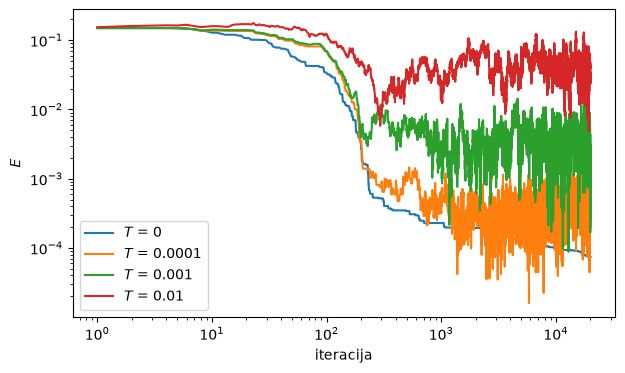

In [11]:
temperature = [0, 1e-4, 1e-3, 1e-2]
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for T in temperature:
    t_r, E_r, p_r, _ = relaksacija_mc(t0, ref6, n_iter=20_000, korak=0.02, T=T, prilagodi=False,
                                      rng=np.random.default_rng(3))
    ax.loglog(np.arange(1, len(E_r) + 1), E_r, label=f"$T$ = {T:g}")
    druga = E_r[len(E_r) // 2:]
    print(f"T = {T:g}: <E> (2. polovica) = {druga.mean():.2e} +- {druga.std():.1e}, "
          f"delež sprejetih = {p_r[len(p_r)//2:].mean():.2f}, A = {ploscina(t_r):.3f}")
ax.set_xlabel("iteracija")
ax.set_ylabel("$E$")
ax.legend()
plt.show()